In [1]:
from typing import TypedDict, Literal, Annotated
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.messages import AnyMessage, HumanMessage, AIMessage

def afficher_graphe(graphe):
    try:
        display(Image(graphe.get_graph().draw_mermaid_png()))
    except Exception:
        print(graphe.get_graph().draw_mermaid())   # si pas d'accès internet : le code du schéma

In [2]:
class EtatSimple(TypedDict):
    messages: list[AnyMessage]
    compteur: int

In [3]:
def noeud_inverser(etat: EtatSimple) -> dict:
    texte = etat["messages"][-1].content
    reponse = AIMessage(f"Texte inversé : {texte.upper()[::-1]}")
    return {"messages": etat["messages"] + [reponse], "compteur": etat["compteur"] + 1}

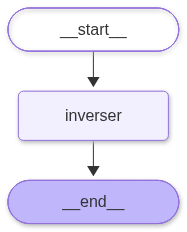

In [4]:
workflow = StateGraph(EtatSimple)
workflow.add_node("inverser", noeud_inverser)
workflow.add_edge(START, "inverser")
workflow.add_edge("inverser", END)

graphe = workflow.compile()
afficher_graphe(graphe)

In [5]:
resultat = graphe.invoke({"messages": [HumanMessage("Bonjour LangGraph")], "compteur": 0})

for message in resultat["messages"]:
    message.pretty_print()
print("Compteur :", resultat["compteur"])

================================ Human Message =================================

Bonjour LangGraph
================================== Ai Message ==================================

Texte inversé : HPARGGNAL RUOJNOB
Compteur : 1


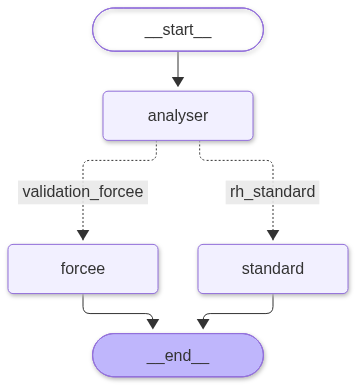

In [6]:
class EtatEmploye(TypedDict):
    nom: str
    age: int
    salaire: float
    decision: Literal["rh_standard", "validation_forcee"]
    resultat: str

def analyser(etat: EtatEmploye) -> dict:
    if etat["age"] <= 30 and etat["salaire"] <= 40000:
        return {"decision": "rh_standard"}
    return {"decision": "validation_forcee"}

def traitement_standard(etat: EtatEmploye) -> dict:
    return {"resultat": f"Demande de {etat['nom']} envoyée au traitement RH standard"}

def validation_forcee(etat: EtatEmploye) -> dict:
    return {"resultat": f"Demande de {etat['nom']} envoyée à la validation RH forcée"}

def routeur(etat: EtatEmploye) -> str:
    return etat["decision"]          # le nom de la branche à suivre

workflow = StateGraph(EtatEmploye)
workflow.add_node("analyser", analyser)
workflow.add_node("standard", traitement_standard)
workflow.add_node("forcee", validation_forcee)
workflow.add_edge(START, "analyser")
workflow.add_conditional_edges("analyser", routeur, {
    "rh_standard": "standard",
    "validation_forcee": "forcee",
})
workflow.add_edge("standard", END)
workflow.add_edge("forcee", END)

graphe_rh = workflow.compile()
afficher_graphe(graphe_rh)

In [7]:
print(graphe_rh.invoke({"nom": "Mohamed", "age": 23, "salaire": 20000})["resultat"])
print(graphe_rh.invoke({"nom": "Yassine", "age": 55, "salaire": 65000})["resultat"])

Demande de Mohamed envoyée au traitement RH standard
Demande de Yassine envoyée à la validation RH forcée


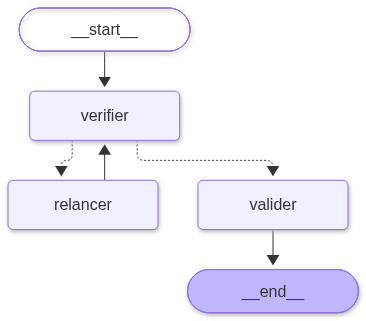

In [8]:
class EtatDossier(TypedDict):
    nom: str
    documents_manquants: int
    relances: int
    statut: str

def verifier_dossier(etat: EtatDossier) -> dict:
    statut = "incomplet" if etat["documents_manquants"] > 0 else "complet"
    print(f"Vérification du dossier de {etat['nom']} : {statut} ({etat['documents_manquants']} manquant(s))")
    return {"statut": statut}

def relancer_employe(etat: EtatDossier) -> dict:
    print(f"   📧 Relance n°{etat['relances'] + 1}")
    return {"relances": etat["relances"] + 1, "documents_manquants": etat["documents_manquants"] - 1}

def valider_dossier(etat: EtatDossier) -> dict:
    print("✅ Dossier validé")
    return {"statut": "validé"}

def routeur_dossier(etat: EtatDossier) -> str:
    return "relancer" if etat["statut"] == "incomplet" else "valider"

workflow = StateGraph(EtatDossier)
workflow.add_node("verifier", verifier_dossier)
workflow.add_node("relancer", relancer_employe)
workflow.add_node("valider", valider_dossier)
workflow.add_edge(START, "verifier")
workflow.add_conditional_edges("verifier", routeur_dossier, {"relancer": "relancer", "valider": "valider"})
workflow.add_edge("relancer", "verifier")     # ← retour en arrière : c'est la boucle
workflow.add_edge("valider", END)

graphe_dossier = workflow.compile()
afficher_graphe(graphe_dossier)

In [9]:
graphe_dossier.invoke({"nom": "Mohamed", "documents_manquants": 3, "relances": 0, "statut": ""})

Vérification du dossier de Mohamed : incomplet (3 manquant(s))
   📧 Relance n°1
Vérification du dossier de Mohamed : incomplet (2 manquant(s))
   📧 Relance n°2
Vérification du dossier de Mohamed : incomplet (1 manquant(s))
   📧 Relance n°3
Vérification du dossier de Mohamed : complet (0 manquant(s))
✅ Dossier validé


{'nom': 'Mohamed', 'documents_manquants': 0, 'relances': 3, 'statut': 'validé'}

In [10]:
from langchain_ollama import ChatOllama
from langchain.tools import tool
from langgraph.prebuilt import ToolNode

class EtatAgent(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

@tool
def additionner(a: float, b: float) -> float:
    """Additionne deux nombres a et b."""
    print(f"  🔧 additionner({a}, {b})")
    return a + b

@tool
def multiplier(a: float, b: float) -> float:
    """Multiplie deux nombres a et b."""
    print(f"  🔧 multiplier({a}, {b})")
    return a * b

outils = [additionner, multiplier]
llm = ChatOllama(model="qwen3:4b", temperature=0, reasoning=True)
llm_avec_outils = llm.bind_tools(outils)    # le LLM connaît maintenant les outils

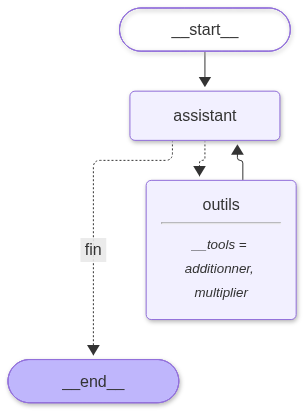

In [11]:
def assistant(etat: EtatAgent) -> dict:
    return {"messages": [llm_avec_outils.invoke(etat["messages"])]}

def doit_continuer(etat: EtatAgent) -> str:
    return "outils" if etat["messages"][-1].tool_calls else "fin"

workflow = StateGraph(EtatAgent)
workflow.add_node("assistant", assistant)
workflow.add_node("outils", ToolNode(outils))     # exécute les tool_calls du dernier message
workflow.add_edge(START, "assistant")
workflow.add_conditional_edges("assistant", doit_continuer, {"outils": "outils", "fin": END})
workflow.add_edge("outils", "assistant")         # après les outils, retour au LLM

graphe_agent = workflow.compile()
afficher_graphe(graphe_agent)

In [12]:
question = {"messages": [HumanMessage("Ajoute 5 à 80, puis multiplie le résultat par 23.")]}

for etape in graphe_agent.stream(question, stream_mode="values"):
    etape["messages"][-1].pretty_print()

================================ Human Message =================================

Ajoute 5 à 80, puis multiplie le résultat par 23.
================================== Ai Message ==================================
Tool Calls:
  additionner (2bc6465e-1a06-47d9-8546-dcb42d8eaec5)
 Call ID: 2bc6465e-1a06-47d9-8546-dcb42d8eaec5
  Args:
    a: 80
    b: 5
  multiplier (d35fe933-d160-4c06-8ae8-84e99ef077ec)
 Call ID: d35fe933-d160-4c06-8ae8-84e99ef077ec
  Args:
    a: 85
    b: 23
  🔧 additionner(80.0, 5.0)
  🔧 multiplier(85.0, 23.0)
================================= Tool Message =================================
Name: multiplier

1955.0
================================== Ai Message ==================================
Tool Calls:
  additionner (14a1314a-bf1b-495a-ab49-82d2de132f52)
 Call ID: 14a1314a-bf1b-495a-ab49-82d2de132f52
  Args:
    a: 85
    b: 1955
  🔧 additionner(85.0, 1955.0)
================================= Tool Message =================================
Name: additionner

2040.0
=

In [13]:
from langgraph.checkpoint.memory import InMemorySaver

graphe_memoire = workflow.compile(checkpointer=InMemorySaver())
config = {"configurable": {"thread_id": "1"}}

graphe_memoire.invoke({"messages": [HumanMessage("Je m'appelle Ali.")]}, config=config)
resultat = graphe_memoire.invoke({"messages": [HumanMessage("Comment je m'appelle ?")]}, config=config)
print(resultat["messages"][-1].content)

print("\nMessages en mémoire :", len(graphe_memoire.get_state(config).values["messages"]))

Je m'appelle Ali.

Messages en mémoire : 4
